<a href="https://colab.research.google.com/github/swarnapatro/AI_KickStart/blob/main/1_LangGraph_Basics_Support_Triage_Ollama.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LangGraph 101 — Build an LLM Workflow You Can Actually Explain

**Notebook 1 of 2** · Pure LangGraph, no LangSmith yet.
**Runs in Google Colab. Open-source model served by Ollama. No API key. No credit card.**

### Who this is for
Freshers, working professionals, coders and non-coders. If you can read a Python function, you can follow this.
**Not a coder?** Read the `#` comment lines inside each code cell and the grey "Cell guide" above it. Then look at the printed output below the cell.

### Where does the AI model run?
The AI model is served by **[Ollama](https://ollama.com)**. You have two ways to run this notebook, and the setup cell (Step 0) handles both:

| Option | Where the model runs | What you do |
|---|---|---|
| **A. Inside Colab (default)** | On Colab's free machine | Nothing. Step 0 installs Ollama and downloads the model for you (about 5–8 minutes the first time). Choose a **T4 GPU** first. |
| **B. On your own laptop** | On the Ollama already installed on your laptop | Expose your laptop's Ollama with a tunnel and paste its address in Step 0 (instructions are in Step 0). |

> The LangGraph code after Step 0 is **identical** for both options. Only the place where the model runs changes.

### Before you run anything (Option A)
In Colab: **Runtime → Change runtime type → Hardware accelerator → T4 GPU → Save.**
Without a GPU everything still works, only slower.

### What you will learn
| # | Concept | One-line meaning |
|---|---------|------------------|
| 1 | **State** | The shared "clipboard" that travels through the workflow |
| 2 | **Node** | A Python function that does one job and updates the clipboard |
| 3 | **Edge** | An arrow saying "after this node, go there" |
| 4 | **Conditional edge** | An arrow that *decides* where to go, based on the clipboard |
| 5 | **Compile** | Turn the drawing into a runnable object |
| 6 | **Execution** | `invoke()` for the answer, `stream()` to watch it think |
| 7 | **Reducer** | A rule for *merging* updates instead of overwriting |
| 8 | **Checkpointer** | Memory, so the workflow can pause and resume |

> **Mental model:** LangGraph is a **flowchart you can run**. You draw boxes (nodes) and arrows (edges); LangGraph executes them and carries a dictionary (state) from box to box.

### How to run
Run the cells **top to bottom, one at a time** (click a cell, press **Shift + Enter**). Do not skip cells: later cells use things created by earlier ones.

---
## The business problem: Customer Support Ticket Triage

A SaaS company receives hundreds of support emails a day. Today a human reads each one and decides:

1. Is this **billing**, **technical**, or **general**?
2. Is it **urgent**?
3. What is a good first reply?
4. Does a **human** need to take over?

We will automate steps 1–4 as a workflow.

### The flow we are going to build

```
                     ┌──────────────┐
        START ─────► │  classify    │   (LLM: category + urgency)
                     └──────┬───────┘
                            │  route_by_category  ◄── conditional edge
             ┌──────────────┼──────────────┐
             ▼              ▼              ▼
     ┌─────────────┐ ┌────────────┐ ┌──────────────┐
     │billing_reply│ │ tech_reply │ │general_reply │   (LLM: draft answer)
     └──────┬──────┘ └─────┬──────┘ └──────┬───────┘
            └──────────────┼───────────────┘
                           ▼
                   ┌───────────────┐
                   │ quality_check │   (plain rules: should a human step in?)
                   └───────┬───────┘
                           │  route_after_check  ◄── conditional edge
                  ┌────────┴────────┐
                  ▼                 ▼
           ┌────────────┐          END
           │  escalate  │
           └─────┬──────┘
                 ▼
                END
```

**Why this shape?** It is the smallest flow that uses *every* core LangGraph idea: linear edges, branching, merging, and a second decision point.

---
## 0. Setup — an open-source model served by Ollama

We use **`llama3.1:8b`**, a free open-weights model (about 5 GB download). Ollama is the small program that downloads the model and answers questions with it.

| | |
|---|---|
| Cost | Free |
| API key | None |
| Download time | 3–6 minutes, once per Colab session (instant on a laptop that already has it) |

The model object we build is a normal LangChain chat model, so **every line of LangGraph code below is identical** no matter which model you swap in later.

### Cell guide: install libraries
- **What it does:** downloads the Python libraries this notebook needs (about 1–2 minutes the first time).
- **Input:** nothing.
- **Output:** a few install messages (or nothing if already installed).

In [ ]:
# "%pip install" downloads Python libraries from the internet. "-q" keeps the output quiet.
#   langgraph       -> the main library of this class: build workflows out of nodes and edges
#   langchain-core  -> common building blocks (message types, the chat-model interface)
#   langchain-ollama-> the connector that lets LangChain talk to a model served by Ollama
#   pydantic        -> checks that data has the right shape (we use it to validate the AI's answer)
%pip install -q langgraph langchain-core langchain-ollama pydantic

### Cell guide: choose where Ollama runs, start it, and get the model
- **What it does:** makes sure an Ollama server is reachable and that the model `llama3.1:8b` is available.
  - If you pasted a laptop address into `LAPTOP_OLLAMA_URL`, it uses your laptop (Option B).
  - Otherwise, if Ollama is already running on this machine, it uses that.
  - Otherwise (a fresh Colab) it installs Ollama, starts it, and downloads the model (Option A).
- **Input:** the two settings at the top: `MODEL_NAME` and `LAPTOP_OLLAMA_URL`.
- **Output:** the line `Ollama is running at ...`, then `Model ready: llama3.1:8b`. First run in Colab takes about 3–6 minutes.

<details>
<summary><b>Option B — use the Ollama installed on YOUR laptop from Colab (click to expand)</b></summary>

Colab lives on the internet and cannot see your laptop directly, so we open a **tunnel**: a temporary public web address that forwards to your laptop's Ollama. Do this on your laptop, in a terminal:

1. Make sure the model exists: `ollama pull llama3.1:8b`
2. Allow outside requests: set the environment variable `OLLAMA_ORIGINS=*`, then quit and restart Ollama.
   (Windows PowerShell: `setx OLLAMA_ORIGINS "*"` then restart the Ollama app.)
3. Install [ngrok](https://ngrok.com/download) (free account) and run:
   `ngrok http 11434 --host-header="localhost:11434"`
4. Copy the `https://....ngrok-free.app` address it prints and paste it into `LAPTOP_OLLAMA_URL` below.

Treat that address like a password: anyone who has it can use your laptop's model. Close ngrok when class ends.
</details>

In [ ]:
import shutil           # checks whether a program (ollama) is installed on this machine
import subprocess       # runs command-line programs (like "ollama pull") from Python
import time             # lets us wait a few seconds between checks
import json             # reads the answer that Ollama sends back
import urllib.request   # used to ask Ollama "are you there?"

# ----------------------------- SETTINGS YOU MAY CHANGE -----------------------------
MODEL_NAME = "llama3.1:8b"   # the AI model to use. Smaller/faster alternative: "llama3.2:3b"
LAPTOP_OLLAMA_URL = ""       # Option B only: paste your ngrok address here, e.g. "https://abc123.ngrok-free.app"
                             # Leave it as "" to run Ollama inside Colab (Option A) or on your own computer.
# -----------------------------------------------------------------------------------

# This is the address of the Ollama server that the rest of the notebook will talk to.
# 11434 is Ollama's standard port number.
OLLAMA_URL = LAPTOP_OLLAMA_URL.strip().rstrip("/") or "http://localhost:11434"


def ollama_is_running(url):
    # Input : an address. Output: True if an Ollama server answers there, otherwise False.
    try:
        urllib.request.urlopen(url, timeout=5)
        return True
    except Exception:
        return False


def models_available(url):
    # Input : an address. Output: a list of model names installed on that Ollama, e.g. ["llama3.1:8b", ...]
    with urllib.request.urlopen(url + "/api/tags", timeout=10) as reply:
        return [m["name"] for m in json.load(reply)["models"]]


if LAPTOP_OLLAMA_URL.strip():
    # ---- Option B: the model lives on the presenter's / student's laptop ----
    if not ollama_is_running(OLLAMA_URL):
        raise RuntimeError(f"Cannot reach {OLLAMA_URL}. Is ngrok still running on your laptop?")
    print("Ollama is running at", OLLAMA_URL, "(your laptop)")
    if not any(name.startswith(MODEL_NAME) for name in models_available(OLLAMA_URL)):
        raise RuntimeError(f"Model {MODEL_NAME} is not on your laptop. Run: ollama pull {MODEL_NAME}")
else:
    # ---- Option A: Ollama runs on this machine (Colab, or a laptop running Jupyter) ----
    if not ollama_is_running(OLLAMA_URL):
        if shutil.which("ollama") is None:
            # Ollama is not installed (typical for a fresh Colab). Install it.
            # zstd is a small tool the Ollama installer needs.
            subprocess.run("apt-get install -y -q zstd > /dev/null 2>&1; curl -fsSL https://ollama.com/install.sh | sh",
                           shell=True, check=True)
        # Start the Ollama server in the background, then wait up to 30 seconds for it to wake up.
        subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        for _ in range(30):
            if ollama_is_running(OLLAMA_URL):
                break
            time.sleep(1)
    print("Ollama is running at", OLLAMA_URL)
    # Download the model. If it is already on the machine this finishes instantly.
    # capture_output=True keeps the long download progress bar out of the notebook.
    subprocess.run(["ollama", "pull", MODEL_NAME], check=True, capture_output=True)

print("Model ready:", MODEL_NAME)

Ollama is running at http://localhost:11434
Model ready: llama3.1:8b


### Cell guide: connect LangChain to the model and run a smoke test
- **What it does:** creates the object `llm` (our AI model) and asks it one simple question to prove it answers.
- **Input:** `MODEL_NAME` and `OLLAMA_URL` from the previous cell.
- **Output:** three words from the model (for example `Hello, how are`). If you see text, the model works.
- **If you see "connection refused":** Ollama is not running. Re-run the previous cell.

In [ ]:
import warnings
warnings.filterwarnings("ignore")        # hides harmless yellow warnings so the class output stays clean

# ChatOllama is the connector between LangChain/LangGraph and a model served by Ollama.
from langchain_ollama import ChatOllama

llm = ChatOllama(
    model=MODEL_NAME,        # which model to use
    base_url=OLLAMA_URL,     # which Ollama server to talk to (Colab, or your laptop)
    temperature=0,           # 0 = same question gives same answer (best for teaching). Higher = more creative.
    num_predict=256,         # maximum length of any answer, in tokens (a token is about 3/4 of a word)
)

# Smoke test.  Input: a question as plain text.  Output: an AI message; ".content" is its text.
print(llm.invoke("Reply with exactly three words.").content)

I'm ready now.


<details>
<summary><b>Model too slow, or running out of memory? Click for other options.</b></summary>

**Smaller, faster model (about 2 GB):** change the setting in the Step 0 cell and re-run it:
```python
MODEL_NAME = "llama3.2:3b"
```

**Even smaller (about 1 GB, weaker answers):**
```python
MODEL_NAME = "qwen2.5:1.5b"
```

**Model on your laptop is not found?** Run `ollama list` in a laptop terminal and use the exact name shown.

**Everything after Step 0 stays identical** whichever model you choose. That is the point of LangChain's common interface.
</details>

---
## 1. State — the clipboard

**State is a `TypedDict`.** It lists *every* piece of data the workflow is allowed to carry.

Rules to remember:

- Every node receives the **whole** state.
- Every node returns a **small dict containing only the keys it changed**.
- LangGraph merges that small dict back into the state for you.
- If a key is not declared here, nodes cannot use it. **Declare first, use later.**

`Annotated[list[str], operator.add]` on `log` is a **reducer** — instead of overwriting, new items get *appended*. More on this in Section 7.

### Cell guide: define the state
- **What it does:** declares the "form" that travels through the workflow: which fields exist and what type each is.
- **Input:** nothing (it only defines a structure).
- **Output:** the list of field names: `ticket_id`, `customer_tier`, `message`, `category`, `urgency`, `draft_reply`, `needs_human`, `reason`, `log`.

In [ ]:
import operator                              # gives us operator.add, the "append two lists" rule used by the reducer
from typing import Annotated, TypedDict      # TypedDict = a dictionary with named, typed fields; Annotated = attach a rule to a field
from typing_extensions import Literal        # Literal = "the value must be exactly one of these choices"


class TicketState(TypedDict):
    # --- inputs (given to us at the start) ---
    ticket_id: str                                        # e.g. "T-1001"
    customer_tier: Literal['free', 'pro', 'enterprise']   # only these three values are allowed
    message: str                                          # the customer's email text

    # --- produced by the classify node ---
    category: str        # billing | technical | general
    urgency: str         # low | high

    # --- produced by the reply nodes ---
    draft_reply: str     # the AI-written first response

    # --- produced by the quality_check node ---
    needs_human: bool    # True = a person must review before sending
    reason: str          # why (or "safe to auto-send")

    # --- append-only audit trail (this one has a reducer) ---
    # IMPORTANT LINE: Annotated[..., operator.add] means "when a node returns log items, ADD them to the
    # existing list instead of replacing it".
    log: Annotated[list[str], operator.add]


print(list(TicketState.__annotations__))

['ticket_id', 'customer_tier', 'message', 'category', 'urgency', 'draft_reply', 'needs_human', 'reason', 'log']


> **Point to remember #1**
> State is a *contract*. Nodes never call each other directly — they only read and write state. That is what makes every node independently testable.

---
## 2. Getting reliable output from an open model

An open model happily replies *"Sure! This looks like a billing issue :)"* when you wanted the single word `billing`.

The production-grade pattern, which works with **any** model:

1. Ask for **JSON only**, and show the exact shape.
2. **Extract** the JSON with a regex (models love adding chatter around it).
3. **Validate** it with Pydantic.
4. **Fall back** to a safe default if anything fails.

Never let a malformed LLM response crash your workflow.

### Cell guide: the classifier (prompt → extract → validate → fallback)
- **What it does:** builds a function `classify_ticket(message)` that asks the AI to label a ticket, cleans up the reply, checks it, and never crashes.
- **Input:** a customer message (text), for example `"I was charged twice this month and my card is now overdrawn!"`.
- **Output:** a `Triage` object with two fields. For the example above the last line prints something like `category='billing' urgency='high'`.

In [ ]:
import json, re                                  # json = read JSON text; re = "regular expressions", a search-by-pattern tool
from pydantic import BaseModel, ValidationError   # BaseModel = define a data shape; ValidationError = raised when data does not fit it


class Triage(BaseModel):
    # The ONLY shape of answer we accept from the AI. Anything else is rejected.
    category: Literal['billing', 'technical', 'general']
    urgency: Literal['low', 'high']


# The instructions we send to the AI. We show it the exact output format we want.
TRIAGE_PROMPT = (
    'You are a support ticket classifier.\n'
    'Reply with ONLY a JSON object and nothing else, in exactly this shape:\n'
    '{"category": "billing", "urgency": "low"}\n'
    'category must be one of: billing, technical, general.\n'
    'urgency must be "high" if the customer is blocked, losing money, or angry; otherwise "low".\n\n'
    'Ticket: '
)


def extract_json(text: str) -> dict:
    # Input : any text, e.g.  'Sure! {"category": "billing", "urgency": "low"} Hope that helps'
    # Output: the JSON part as a Python dict, e.g. {'category': 'billing', 'urgency': 'low'}
    # The pattern \{.*?\} means "find the first { ... } block", ignoring the chatter around it.
    match = re.search(r'\{.*?\}', text, re.DOTALL)
    if not match:
        raise ValueError('no JSON object found')
    return json.loads(match.group())


def classify_ticket(message: str) -> Triage:
    # Input : the customer's message.   Output: a validated Triage(category, urgency).
    raw = llm.invoke(TRIAGE_PROMPT + message).content          # 1. ask the AI
    try:
        return Triage(**extract_json(raw))                     # 2. extract the JSON  3. validate it
    except (ValueError, ValidationError, json.JSONDecodeError):
        return Triage(category='general', urgency='low')       # 4. safe fallback: never crash


# Quick test of the helper alone (no AI involved).  Notice how the chatter is ignored:
print(extract_json('Sure! {"category": "billing", "urgency": "low"} Hope that helps'))

# Quick test of the whole classifier (calls the AI) - no graph involved yet:
classify_ticket('I was charged twice this month and my card is now overdrawn!')

{'category': 'billing', 'urgency': 'low'}


Triage(category='billing', urgency='high')

> **Point to remember #2**
> Parse defensively. *Prompt → extract → validate → fallback* is four lines of code that prevents most 3 a.m. incidents.
>
> *(Note: some models support `llm.with_structured_output(Triage)` as a shortcut. Smaller open models are less consistent with it, so we do it manually — and the manual version works everywhere.)*

---
## 3. Nodes — the boxes

**A node is just a Python function** with this shape:

```python
def my_node(state: TicketState) -> dict:
    ...
    return {'some_key': new_value}     # a partial update
```

That is the entire API. No base class, no decorator, no inheritance.

Notice that `quality_check` and `escalate` below call **no LLM at all** — nodes are ordinary code. Use an LLM only where judgement is genuinely needed; use plain Python where rules are enough. Cheaper, faster, and 100% testable.

### Cell guide: Node 1 — classify
- **What it does:** reads the customer message from the state, asks the classifier, and writes `category` and `urgency` back.
- **Input (from state):** `message`.
- **Output (returned to state):** `category`, `urgency`, and one line added to `log`. Example: `{'category': 'billing', 'urgency': 'high', 'log': ['classified as billing/high']}`.
- Nothing prints here; we only *define* the function. It runs later, inside the graph.

In [ ]:
# ---------- NODE 1: classify ----------
def classify(state: TicketState) -> dict:
    result = classify_ticket(state['message'])          # read the message from the clipboard (state)
    return {                                            # write back ONLY what this node produced
        'category': result.category,
        'urgency': result.urgency,
        'log': [f'classified as {result.category}/{result.urgency}'],   # the reducer APPENDS this line
    }

### Cell guide: Nodes 2–4 — the three reply writers
- **What it does:** defines one helper `_write_reply` that asks the AI to draft a short reply, plus three tiny nodes that each give the AI a different role (billing specialist, technical engineer, friendly agent).
- **Input (from state):** `message`, `customer_tier`, `urgency`, `category`.
- **Output (returned to state):** `draft_reply` (the AI's text) and one line added to `log`, e.g. `'drafted billing reply'`.
- Small, focused prompts beat one giant prompt.

In [ ]:
# ---------- NODES 2-4: one reply writer per category ----------
# One shared helper, three different "personas" (roles given to the AI).

def _write_reply(state: TicketState, persona: str) -> dict:
    # Input : the state, and a one-line role description (persona).
    # Output: {'draft_reply': <AI text>, 'log': [...]}
    prompt = (
        f'{persona}\n'
        f'Customer tier: {state["customer_tier"]}. Urgency: {state["urgency"]}.\n'
        f'Write a short, warm reply of at most 4 sentences. '
        f'Do not invent policy, refund amounts, or dates.\n\n'      # guard-rail: stop the AI making things up
        f'Ticket: {state["message"]}'
    )
    reply = llm.invoke(prompt).content.strip()          # ask the AI; .strip() removes stray blank space
    return {'draft_reply': reply, 'log': [f'drafted {state["category"]} reply']}


def billing_reply(state: TicketState) -> dict:
    return _write_reply(state, 'You are a billing support specialist.')


def technical_reply(state: TicketState) -> dict:
    return _write_reply(state, 'You are a technical support engineer. Suggest one concrete first troubleshooting step.')


def general_reply(state: TicketState) -> dict:
    return _write_reply(state, 'You are a friendly customer success agent.')

### Cell guide: Nodes 5–6 — quality_check and escalate (no AI)
- **What it does:** `quality_check` applies simple business rules to decide if a human must review the reply. `escalate` hands the ticket to the human queue.
- **Input (from state):** `message`, `draft_reply`, `urgency`, `customer_tier` (and `reason` for `escalate`).
- **Output (returned to state):**
  - `quality_check` → `needs_human` (True/False), `reason`, and a `log` line. Example: `{'needs_human': False, 'reason': 'safe to auto-send', 'log': ['passed quality check']}`.
  - `escalate` → a `log` line, e.g. `'escalated to human queue (sensitive topic detected)'`.
- **Rules used:** (1) risky words such as *refund, cancel, legal* → human. (2) high urgency + enterprise customer → human. Otherwise → safe to auto-send.

In [ ]:
# ---------- NODE 5: quality_check (pure rules, zero LLM calls) ----------
def quality_check(state: TicketState) -> dict:
    risky_words = ['refund', 'cancel', 'legal', 'lawsuit', 'gdpr', 'data breach']
    # Join the customer's message and our draft into one lowercase text so we can search it.
    text = (state['message'] + ' ' + state['draft_reply']).lower()

    # Rule 1: any risky word anywhere in the text -> a human must look.
    if any(word in text for word in risky_words):
        return {'needs_human': True, 'reason': 'sensitive topic detected',
                'log': ['flagged: sensitive topic']}

    # Rule 2: an urgent ticket from an enterprise customer (they pay for fast response) -> a human must look.
    if state['urgency'] == 'high' and state['customer_tier'] == 'enterprise':
        return {'needs_human': True, 'reason': 'high-urgency enterprise customer',
                'log': ['flagged: enterprise SLA']}

    # Otherwise the AI's draft can be sent automatically.
    return {'needs_human': False, 'reason': 'safe to auto-send',
            'log': ['passed quality check']}


# ---------- NODE 6: escalate ----------
def escalate(state: TicketState) -> dict:
    # In real life: create a Zendesk/Jira ticket, page the on-call agent, post to Slack.
    # Here we simply record the hand-off in the log.
    return {'log': [f'escalated to human queue ({state["reason"]})']}

> **Point to remember #3**
> Return **only what changed**. Returning the whole state technically works, but it hides bugs and makes traces unreadable.
>
> **Point to remember #4**
> Not every node needs an LLM. Deterministic nodes are free, instant, and easy to unit-test.

---
## 4. Conditional edges — the decisions

A **router** is a function that reads state and returns a **string: the name of the next step**.

It returns a *label*, not data. It must not modify state.

### Cell guide: the two routers
- **What it does:** defines the two decision functions of our flowchart.
  - `route_by_category` → picks which reply writer runs next.
  - `route_after_check` → picks whether to escalate or finish.
- **Input (from state):** `category` for the first, `needs_human` for the second.
- **Output:** a node name. Examples: `category='billing'` → `'billing_reply'`; `needs_human=True` → `'escalate'`; `needs_human=False` → `'done'`.
- Nothing prints; the graph will call these for us.

In [ ]:
def route_by_category(state: TicketState) -> str:
    # Input : state['category'] ("billing", "technical" or anything else)
    # Output: the NAME of the next node.
    return {
        'billing': 'billing_reply',
        'technical': 'technical_reply',
    }.get(state['category'], 'general_reply')      # .get(..., default): anything unexpected goes to general_reply


def route_after_check(state: TicketState) -> str:
    # Input : state['needs_human'] (True/False)
    # Output: 'escalate' when a human is needed, otherwise 'done' (which we later map to END)
    return 'escalate' if state['needs_human'] else 'done'

> **Point to remember #5**
> Always give routers a **safe default**. If the model returns something unexpected, the graph should still finish instead of crashing.

---
## 5. Building the graph — nodes + edges + compile

Four verbs, in this order:

| Verb | What it does |
|------|--------------|
| `add_node('name', fn)` | Put a box on the canvas |
| `add_edge('a', 'b')` | Fixed arrow: always a → b |
| `add_conditional_edges('a', router, mapping)` | Branching arrow: a → whatever the router returns |
| `.compile()` | Validate the wiring and return a runnable app |

`START` and `END` are built-in special nodes.

### Cell guide: assemble and compile the graph
- **What it does:** places the 6 boxes, draws the arrows, and compiles the result into `app`.
- **Input:** the node functions and routers defined above.
- **Output:** `Graph compiled.` If you made a wiring mistake, you would get an error here instead.

In [ ]:
from langgraph.graph import StateGraph, START, END     # StateGraph = the builder; START/END = built-in entry and exit points

builder = StateGraph(TicketState)    # an empty canvas that knows our state "form"

# 1. boxes: add_node('name used in arrows', python_function)
builder.add_node('classify', classify)
builder.add_node('billing_reply', billing_reply)
builder.add_node('technical_reply', technical_reply)
builder.add_node('general_reply', general_reply)
builder.add_node('quality_check', quality_check)
builder.add_node('escalate', escalate)

# 2. fixed arrows: "after the first, always go to the second"
builder.add_edge(START, 'classify')                    # the workflow begins at classify
builder.add_edge('billing_reply', 'quality_check')     # all three writers merge into quality_check
builder.add_edge('technical_reply', 'quality_check')
builder.add_edge('general_reply', 'quality_check')
builder.add_edge('escalate', END)                      # escalate is the last step

# 3. branching arrows: the router function decides where to go
builder.add_conditional_edges(
    'classify',                 # from this node
    route_by_category,          # ask this function
    {                           # map its return value -> destination node
        'billing_reply': 'billing_reply',
        'technical_reply': 'technical_reply',
        'general_reply': 'general_reply',
    },
)

builder.add_conditional_edges(
    'quality_check',
    route_after_check,
    {'escalate': 'escalate', 'done': END},     # 'done' means "finish the workflow"
)

# 4. compile: check the wiring and produce a runnable app
app = builder.compile()
print('Graph compiled.')

Graph compiled.


> **Point to remember #6**
> `.compile()` is your first test. It fails loudly on typos, unreachable nodes, and dead ends. Compile early, compile often.

### Visualise it
A picture beats reading wiring code. `draw_mermaid()` always works (plain text); the PNG version needs internet.

### Cell guide: print the graph as text
- **What it does:** prints the graph in "Mermaid" format, a text description of a flowchart.
- **Input:** `app`.
- **Output:** lines like `classify -.-> billing_reply;` (dotted arrows are conditional). You can paste this text into [mermaid.live](https://mermaid.live) to see a picture.

In [ ]:
print(app.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	classify(classify)
	billing_reply(billing_reply)
	technical_reply(technical_reply)
	general_reply(general_reply)
	quality_check(quality_check)
	escalate(escalate)
	__end__([<p>__end__</p>]):::last
	__start__ --> classify;
	billing_reply --> quality_check;
	classify -.-> billing_reply;
	classify -.-> general_reply;
	classify -.-> technical_reply;
	general_reply --> quality_check;
	quality_check -. &nbsp;done&nbsp; .-> __end__;
	quality_check -.-> escalate;
	technical_reply --> quality_check;
	escalate --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



### Cell guide: draw the graph as a picture (optional)
- **What it does:** asks a free website to turn the graph into a PNG image and shows it.
- **Input:** `app` (needs internet).
- **Output:** the flowchart picture, or the message `Skipping image render` if the website is unreachable. Both are fine.

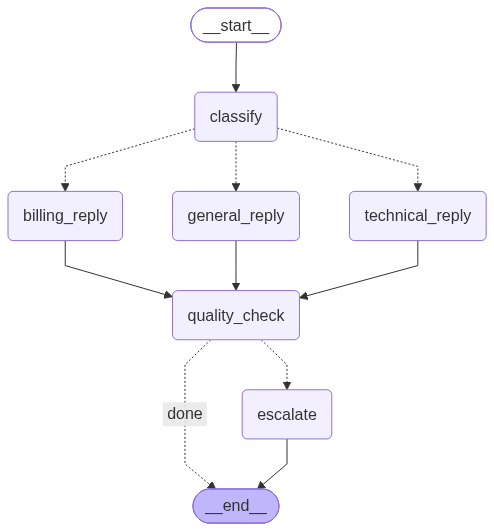

In [ ]:
# Optional: rendered picture
from IPython.display import Image, display      # tools to show images inside a notebook
try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print('Skipping image render:', e)          # no internet / site busy: not a problem, carry on

---
## 6. Execution — running the workflow

`invoke(input_dict)` runs the whole graph and returns the **final state**.

You only pass the keys you actually have. LangGraph fills in the rest as nodes produce them.

### Cell guide: run one ticket through the graph
- **What it does:** sends one billing ticket through the workflow and prints the final state.
- **Input:** a dictionary `ticket` with `ticket_id`, `customer_tier`, `message` and an empty `log`.
- **Output:** category, urgency, whether a human is needed (and why), the AI's draft reply, and the audit log showing every step taken.
- **Expected:** category `billing`; the log has 3 lines (classified, drafted, quality check). The exact wording of the reply varies a little.
- **Time:** 5–60 seconds (two AI calls), longer the first time while the model loads into memory.

In [ ]:
ticket = {                                   # INPUT: only the fields we know at the start
    'ticket_id': 'T-1001',
    'customer_tier': 'pro',
    'message': 'I was billed twice for July. Please check my invoice.',
    'log': [],                               # start with an empty audit trail
}

final = app.invoke(ticket)                   # RUN the whole workflow. OUTPUT: the final state (a dict)

print('category   :', final['category'])
print('urgency    :', final['urgency'])
print('needs_human:', final['needs_human'], '-', final['reason'])
print('\n--- draft reply ---\n', final['draft_reply'])
print('\n--- audit log ---')
for line in final['log']:
    print(' *', line)

category   : billing
urgency    : low
needs_human: False - safe to auto-send

--- draft reply ---
 Hi there! I'd be happy to help you review your invoice. I'll take a look at your account to see what's going on with the duplicate charge for July. Can you please confirm your account name and email address so I can quickly locate your information?

--- audit log ---
 * classified as billing/low
 * drafted billing reply
 * passed quality check


### Try three different tickets
Watch the path change without you editing a single line of graph code. **That** is the value of conditional edges.

### Cell guide: run three more tickets
- **What it does:** loops over three tickets (a technical bug, an urgent enterprise outage, a general question) and prints one summary line for each.
- **Input:** the list `tickets`.
- **Output:** one line per ticket: `ticket id, category, urgency, human=True/False (reason)`.
- **Typical result:** T-1002 → technical; T-1003 → technical + high urgency + `human=True` (enterprise rule); T-1004 → general. Small models can occasionally label differently; that is a good talking point.

In [ ]:
tickets = [
    {'ticket_id': 'T-1002', 'customer_tier': 'free',
     'message': 'The mobile app crashes every time I open Reports.', 'log': []},
    {'ticket_id': 'T-1003', 'customer_tier': 'enterprise',
     'message': 'Our whole team cannot log in. Production is down. This is critical.', 'log': []},
    {'ticket_id': 'T-1004', 'customer_tier': 'pro',
     'message': 'Do you have a dark mode on the roadmap?', 'log': []},
]

for t in tickets:                            # repeat the same steps for each ticket
    r = app.invoke(t)                        # run the workflow; r is the final state
    # f"..." builds a text line; {r['category']:<10} means "pad to 10 characters" so columns line up
    print(f"{t['ticket_id']}  {r['category']:<10} {r['urgency']:<5} human={str(r['needs_human']):<5} ({r['reason']})")

T-1002  technical  low   human=False (safe to auto-send)
T-1003  technical  high  human=True  (high-urgency enterprise customer)
T-1004  general    low   human=False (safe to auto-send)


### `stream()` — watch it think
`invoke()` gives you the destination. `stream()` gives you the journey — one chunk per node, as it finishes.

Use it for progress bars, live UIs, and answering *"which node is slow / which node broke?"*.

### Cell guide: stream one ticket
- **What it does:** runs ticket T-1003 again, but prints a line as **each node finishes**.
- **Input:** `tickets[1]` (the enterprise outage ticket; Python counts from 0, so index 1 is the second item in the list).
- **Output:** one line per node in order, such as `[classify] -> updated ['category', 'urgency', 'log']`, then the reply node, then `quality_check`, then `escalate` if a human is needed.

In [ ]:
for chunk in app.stream(tickets[1]):                # tickets[1] = T-1003, the enterprise outage ticket
    for node_name, update in chunk.items():         # each chunk looks like {'node name': {fields it changed}}
        print(f'[{node_name}] -> updated {list(update.keys())}')

[classify] -> updated ['category', 'urgency', 'log']
[technical_reply] -> updated ['draft_reply', 'log']
[quality_check] -> updated ['needs_human', 'reason', 'log']
[escalate] -> updated ['log']


> **Point to remember #7**
> `invoke` = final state. `stream` = step-by-step updates. Same graph, two ways to consume it.

---
## 7. Reducers — merge instead of overwrite

Default behaviour: a returned key **replaces** the old value.

```python
return {'category': 'billing'}   # category is now 'billing'; the old value is gone
```

With `Annotated[list[str], operator.add]`, the returned value is **combined** with the old one:

```python
return {'log': ['step done']}    # appended to the existing log
```

That is why `log` collected several entries even though each node returned only one.

**You need a reducer for:** chat message history, accumulating logs, collecting results from parallel branches.
**You do not need one for:** anything where the latest value simply wins (category, urgency, draft_reply).

The most common built-in reducer is `add_messages`, used for chat state:

```python
from langgraph.graph.message import add_messages
messages: Annotated[list, add_messages]
```

### Cell guide: see the reducer's result
- **What it does:** shows the `log` from the first ticket we ran in Section 6.
- **Input:** `final['log']` (from the earlier cell, so run that one first).
- **Output:** a list with one entry per node, e.g. `['classified as billing/low', 'drafted billing reply', 'passed quality check']`. Three nodes each returned one line, yet all three are kept. That is the reducer at work.

In [ ]:
# Proof: the log accumulated instead of being overwritten
final['log']

['classified as billing/low', 'drafted billing reply', 'passed quality check']

> **Point to remember #8**
> A missing reducer is the #1 beginner bug: your list keeps only the last node's contribution. If data seems to be "disappearing", check for a missing `Annotated[..., operator.add]`.

---
## 8. Checkpointer — giving the workflow memory

Add a checkpointer and the graph **saves its state after every node**. That unlocks:

- continuing an existing run with the same `thread_id` (conversation memory),
- inspecting history and time-travelling to any past step,
- pausing for human approval and resuming later.

`InMemorySaver` is for learning. In production use `SqliteSaver` or `PostgresSaver`.

### Cell guide: compile with memory and inspect the saved state
- **What it does:** compiles the same graph again, this time with a memory (`InMemorySaver`), runs a ticket under the thread name `customer-42`, then reads the saved state back.
- **Input:** `tickets[0]` and a `config` naming the thread.
- **Output:**
  - `next node to run : ()` — an empty bracket means the workflow is finished.
  - `saved keys` — the names of all fields that were stored.

In [ ]:
from langgraph.checkpoint.memory import InMemorySaver     # a notebook-friendly memory that lives in RAM

# Same builder, now compiled WITH a memory. IMPORTANT LINE: checkpointer=...
app_with_memory = builder.compile(checkpointer=InMemorySaver())

# thread_id is like a "case number": runs with the same thread_id share one saved history.
config = {'configurable': {'thread_id': 'customer-42'}}
app_with_memory.invoke(tickets[0], config)

snapshot = app_with_memory.get_state(config)              # read back what was saved
print('next node to run :', snapshot.next)                # empty tuple () = finished
print('saved keys       :', sorted(snapshot.values))

next node to run : ()
saved keys       : ['category', 'customer_tier', 'draft_reply', 'log', 'message', 'needs_human', 'reason', 'ticket_id', 'urgency']


### Human-in-the-loop — pause before escalating
`interrupt_before=['escalate']` makes the graph **stop** just before escalating so a human can review, then you resume with `invoke(None, config)`.

### Cell guide: pause, review, resume
- **What it does:** runs a ticket that mentions a *refund* (a risky word, so a human is always required). The graph **pauses** before `escalate`. We print the draft a human would review, then **resume**.
- **Input:** a new ticket `hitl_ticket` and a thread name `hitl-demo`.
- **Output:**
  1. `Paused. Next node: ('escalate',)` — the workflow is waiting for a person.
  2. The AI's draft reply for the human to review.
  3. `Finished. Next node: ()` and the full log ending with `escalated to human queue ...`.

In [ ]:
# A second compiled version of the same graph that STOPS just before the 'escalate' box.
app_hitl = builder.compile(checkpointer=InMemorySaver(),
                           interrupt_before=['escalate'])      # IMPORTANT LINE: the pause point

hitl_ticket = {
    'ticket_id': 'T-2001',
    'customer_tier': 'pro',
    'message': 'I want a refund for my annual plan.',    # the word "refund" forces quality_check to flag it
    'log': [],
}
hitl_config = {'configurable': {'thread_id': 'hitl-demo'}}

app_hitl.invoke(hitl_ticket, hitl_config)                # runs until the pause point, then returns
state_now = app_hitl.get_state(hitl_config)
print('Paused. Next node:', state_now.next)              # ('escalate',) = waiting for a human

print('\n--- draft a human would review ---')
print(state_now.values['draft_reply'])

app_hitl.invoke(None, hitl_config)                       # resume: None means "no new input, just continue"
state_end = app_hitl.get_state(hitl_config)
print('\nFinished. Next node:', state_end.next)          # () = done
for line in state_end.values['log']:
    print(' *', line)

Paused. Next node: ('escalate',)

--- draft a human would review ---
Thank you for reaching out to us about your annual plan. I'd be happy to help you explore your options. Can you please let me know what's led you to want to cancel your plan, so I can better understand your needs? This will help me provide the most suitable solution for you.

Finished. Next node: ()
 * classified as billing/low
 * drafted billing reply
 * flagged: sensitive topic
 * escalated to human queue (sensitive topic detected)


> **Point to remember #9**
> No checkpointer = stateless, one-shot run. With a checkpointer = resumable, inspectable, interruptible. Almost every real deployment wants one.

---
## Cheat sheet — screenshot this

| Task | Code |
|------|------|
| Define state | `class S(TypedDict): field: str` |
| Accumulating field | `Annotated[list, operator.add]` |
| Chat history field | `Annotated[list, add_messages]` |
| Create builder | `StateGraph(S)` |
| Add node | `builder.add_node('name', fn)` |
| Fixed edge | `builder.add_edge('a', 'b')` |
| Entry point | `builder.add_edge(START, 'a')` |
| Exit point | `builder.add_edge('a', END)` |
| Branch | `builder.add_conditional_edges('a', router, {'x': 'nodeX'})` |
| Compile | `app = builder.compile()` |
| With memory | `builder.compile(checkpointer=InMemorySaver())` |
| Pause for a human | `builder.compile(..., interrupt_before=['n'])` |
| Run | `app.invoke({...})` |
| Watch steps | `for c in app.stream({...}): ...` |
| Picture | `app.get_graph().draw_mermaid()` |

### The 9 things to remember

1. **State is a contract** — declare every field up front.
2. **Parse defensively** — prompt for JSON, extract, validate, fall back.
3. **Nodes return partial updates**, not the whole state.
4. **Nodes are plain functions** — an LLM is optional.
5. **Routers return node *names***, and always need a safe default.
6. **`.compile()` validates your wiring** — treat it as a test.
7. **`invoke` = result, `stream` = journey.**
8. **No reducer = overwrite.** Add `operator.add` for anything that should accumulate.
9. **Checkpointer = memory + resume + human-in-the-loop.**

### Common errors and what they actually mean

| Error | Cause | Fix |
|-------|-------|-----|
| `KeyError: 'draft_reply'` | A node read a key no earlier node wrote | Check edge order, or seed a default in the input |
| `ValueError: Node 'x' is not reachable` | No edge leads into `x` | Add `add_edge(...)`, or include `x` in a router mapping |
| Graph never stops | A cycle with no exit condition | Give the router a path to `END`, or add a loop counter to state |
| List keeps only the last value | Missing reducer | `Annotated[list, operator.add]` |
| `Connection refused` / `Cannot reach ...` | Ollama is not running, or the laptop tunnel closed | Re-run the Step 0 setup cell; for Option B restart ngrok and paste the new address |
| `model "..." not found` | The model was not downloaded | Run `ollama pull llama3.1:8b` (the Step 0 cell does it in Colab) |
| Very slow answers | Colab has no GPU, or the model is big | Runtime → Change runtime type → T4 GPU, or use `llama3.2:3b` |
| Random / empty `category` | Model wandered off the JSON format | Your fallback caught it — tighten the prompt or use a bigger model |

---
## Exercises

1. **Easy** — add a `spam` category. New node `spam_reply` returns a canned message and goes straight to `END`.
2. **Medium** — add `sentiment` to `Triage`. If sentiment is `angry`, always escalate.
3. **Medium** — add `attempts: int` to state and build a retry loop: if the draft reply is under 20 characters, send it back to the reply node (max 2 attempts).
4. **Hard** — run `billing_reply` *and* a new `check_account_balance` node in parallel (two edges out of `classify`), then merge their results in `quality_check`.

---
### What is still missing?

Right now, if the workflow misroutes a ticket you would never know. You cannot see which prompt produced which reply, how long each node took, or whether last week's change made things better or worse.

**Notebook 2 fixes exactly that, with LangSmith.**